In [2]:
#############################################
#BASIC PACKAGES
import sys,time,os
from copy import deepcopy as dcopy
import healpy as hp
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
%matplotlib inline

#############################################
#PATH TO SCRIPTS FOLDER
path = '/data/AMARINS/LSSxHI-CODES/scripts/'
sys.path.insert(1, path)
import cross_functions_theory      as cxft
import cross_functions_simulations as cxfs
# it's required healpy  (https://healpy.readthedocs.io/en/latest/index.html)
import handling_data               as hdata

#############################################
## MATPLOTLIB FEATURES
from matplotlib import cm
font = {'weight' : 'bold','size'   : 22}
mpl.rc('font', **font)
mpl.rc('font',   size=209)  #set defaults so that the plots are readable
mpl.rc('axes',   titlesize=20)
mpl.rc('axes',   labelsize=20)
mpl.rc('xtick',  labelsize=20)
mpl.rc('ytick',  labelsize=20)
mpl.rc('legend', fontsize =20)
mpl.rc('figure', titlesize=20)
mpl.rc('text',   usetex=True)
## FURTHER MATPLOTLIB FEATURES
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.markers import MarkerStyle
from matplotlib.transforms import Affine2D
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
#colors = ["#ffffcc", "#a1dab4", "#41b6c4", "#2c7fb8", "#253494"]
colors = ['#ff0000', "#41b6c4", '#0000ff']
my_cmap = ListedColormap(colors, name="my_cmap")
#my_cmap_r = my_cmap.reversed()
#############################################
## NAMASTER (https://namaster.readthedocs.io/en/latest/)
import pymaster as nmt
del_l  = 30
nside  = 256
##############################
b    = nmt.NmtBin.from_nside_linear(nside, nlb=del_l)
leff = b.get_effective_ells()
feff = leff*(leff+1)/2/np.pi

In [3]:
#######
# SIMULATION
prefix    = 'LSSTxLOWZ_40_0001'
gbin_used = 2
pathsims      = '/data/AMARINS/LSSxHI-DATA/simulations/GCxHI/{}/bin{}'.format(prefix,gbin_used)
load_sims     = True
generate_sims = False
varnames      = ['cl_hi_sim', 'cl_kappa_sim', 'cl_cross_sim', 'alm_hi_sim']
nsims_to_use  = 100

if generate_sims:
    itime     = time.time()
    clf1_dict = cxft.cls_from_matrix2dict(clf1)
    clf2_dict = cxft.cls_from_matrix2dict(clf2)
    clcx_dict = cxft.cls_from_matrix2dict(clcx)    
    dict_sims = cxfs.dictionary_cross_simulations_quantities(clf1_dict_=clf1_dict, clf2_dict_=clf2_dict, clcx_dict_=clcx_dict, 
                                                             seed_k=9001, seed_hi=9000, nsims=nsims_to_use,
                                                             show_time=False)
    nbins = dict_sims['sim0']['alm_hi_sim'].shape[0]
    l     = dict_sims['sim0']['l']
    print('Load/organize {0:d} sims: {1:.4f} seg'.format(nsims, time.time()-itime)) 

if load_sims:
    #nsims_to_use=20
    itime          = time.time()
    dict_sims      = cxfs.get_file_simulated_data(pathsims, varnames, nsims_to_use=nsims_to_use)
    print('Load/organize {0:d} sims: {1:.4f} seg'.format(nsims_to_use, time.time()-itime)) 

sim_names = np.asarray( list(dict_sims.keys()) )

Load/organize 100 sims: 118.4676 seg


In [4]:
HDU         = 1 #0: Olivari data. 1: Marins data
pathdir_fg  = '/data/AMARINS/MAPS/FG256'
filename_fg = 'FG_I_256_980mhz1260mhz_30bins_full_L0.fits'#'foreground_cube_FG_256.fits'
MFG_true    = hdata.getmap(dirpath_=pathdir_fg, filename_=filename_fg, healpix_readingformat=0, hdu=HDU)
MASK        = np.ones_like(MFG_true[0])
Mfg         = dcopy(MFG_true)
#if rotate_FG: MFG = np.vstack([hp.Rotator(coord=['G','C']).rotate_map_pixel(imfg) for imfg in MFG])    
    ##########
#sky = pysm3.Sky(nside=nside, preset_strings=["s1","f1"])#
#FGs = pyPSM_multiresolution(nu_min=980,nu_max=1260,nbands=30,sky_model=sky,verbose=False)

In [5]:
dict_sims['sim0'].keys()

dict_keys(['cl_hi_sim', 'cl_kappa_sim', 'cl_cross_sim', 'alm_hi_sim'])

In [6]:
def WICA(X_=None, ns=4):
    from sklearn.decomposition import FastICA
    ica = FastICA(n_components     = ns, whiten = 'arbitrary-variance', algorithm='parallel', fun='logcosh', 
                      fun_args     = None, max_iter=200, tol=0.0001, w_init=None, whiten_solver='svd', 
                      random_state = None)
    S   = ica.fit_transform(X_.T) 
    A   = ica.mixing_
    W   = np.dot( np.linalg.inv(np.dot(A.T,A)), A.T)
    Wfg = np.dot(A,W)
    Xfg = np.dot(Wfg, X_)
    Xhi = X_ - Xfg    
    return {'S':S,'A':A,'W':W,'Wfg':Wfg,'Xfg':Xfg,'Xhi':Xhi,'X':X_}

def MHI_from_simulation(dict_=None, var_='alm_hi_sim', sim_='sim0', nside=256, verbose=False):
    lmax        = dict_[sim_][var_][0].real.astype(int).max()
    mmax        = dict_[sim_][var_][1].real.astype(int).max()
    alm_hi_jsim = dict_[sim_][var_][2:]
    for num in range(alm_hi_jsim.shape[0]):
        alm_hi_num = np.ascontiguousarray(alm_hi_jsim[num,:])
        if not num:  Mhi = hp.alm2map( alm_hi_num,                  nside, pol=False)    
        else:        Mhi = np.vstack(( Mhi, hp.alm2map( alm_hi_num, nside, pol=False) ))      
    return Mhi
    

In [7]:
Mhi = MHI_from_simulation(dict_=dict_sims, var_='alm_hi_sim', sim_='sim0', nside=256, verbose=False)

In [8]:
Xobs0     = Mfg+Mhi
dict_obs0 = WICA(X_=Xobs0, ns=4)

Xobs1     = Mfg+0*Mhi
dict_obs1 = WICA(X_=Xobs1, ns=4)

In [9]:
dict_obs0['Wfg'].shape

(30, 30)

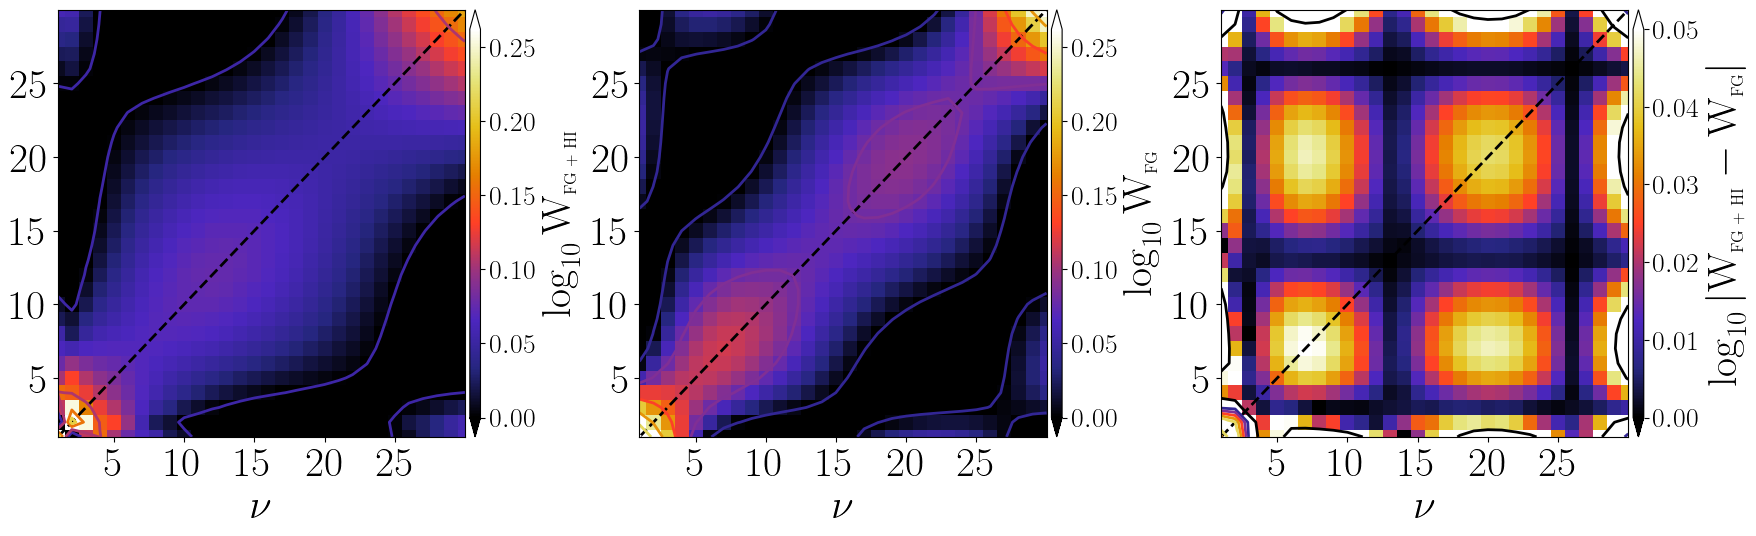

In [10]:
savefigs = True
nmin,nmax = 0,29
############################################################################
ncols,nrows = 3,1
fig, axes   = plt.subplots(nrows=nrows, ncols=ncols)
fig.subplots_adjust(top=nrows*1.,right=ncols*0.9, wspace=0.2,hspace=0.55)
############################################################################
cticks   = [5,10,15,20,25]
CMAP = 'CMRmap'
bwidth=3
WFGs = [dict_obs0['Wfg'],dict_obs1['Wfg'], np.abs(dict_obs0['Wfg']-dict_obs1['Wfg']) ]
#######
for ii, iWfg in enumerate(WFGs):#for ii, ins in enumerate(WFG_dict.keys()):
    ax  = axes[ii] 
    iWfg = iWfg[nmin:nmax+1,nmin:nmax+1]
    #iWfg = dcopy(dict_obs0['Wfg'])
    x   = np.arange(iWfg.shape[0])+1
    y   = np.arange(iWfg.shape[1])+1
    x,y = np.meshgrid(x, y)
    z   = np.log(1+iWfg)
    #######
    if ii<2:im = ax.pcolormesh(x, y, z, cmap=CMAP, vmin=np.log(1+0), vmax=np.log(1+0.3))
    else: im = ax.pcolormesh(x, y, z, cmap=CMAP, vmin=0, vmax=0.05)
    ax.plot(np.arange(iWfg.shape[0])+1,np.arange(iWfg.shape[0])+1, color='black',lw=2,ls='--')
    CS = ax.contour(   x, y, z, cmap=CMAP, extend='both',  linewidths=2,)
    cbar = plt.colorbar(im, ax=ax,extend='both',shrink=1.,pad=0.01,aspect=40, location="right")
    if ii==0:   cbar.set_label(label=r'$\log_{10}\textrm{W}_{\textrm{\large FG + HI}}$', fontsize=30)
    elif ii==1: cbar.set_label(label=r'$\log_{10}\textrm{W}_{\textrm{\large FG}}$', fontsize=30)    
    else:    cbar.set_label(label=r'$\log_{10}|\textrm{W}_{\textrm{\large FG + HI}}-\textrm{W}_{\textrm{\large FG}}|$', fontsize=30)
    cbar.ax.tick_params(labelsize=20) 
    ax.set_xticks(cticks)
    ax.set_yticks(cticks)
    #ax.set_title(r'$n_s = '+ins.split('ns')[1]+'$', fontsize=30)
    ax.set_xlabel(r'$\nu$', fontsize=30)
    ax.tick_params(axis='both', labelsize=30)
    #ax.set_title(r'$n_s = '+ins.split('ns')[1]+'$', fontsize=30)
    ax.set_xlabel(r'$\nu$', fontsize=30)
    #ax.spines['top'   ].set_linewidth(bwidth)  
    #ax.spines['bottom'].set_linewidth(bwidth)
    #ax.spines['left'  ].set_linewidth(bwidth) 
    #ax.spines['right' ].set_linewidth(bwidth)     
    #ax.clabel(CS, inline=True, fontsize=20)
    #CS = ax.contour(10*np.ones_like(x), 10*np.ones_like(x), 10*np.ones_like(x))
    #ax.text(x=3, y=26.2, s=r'$n_s = '+ins.split('ns')[1]+'$', fontdict={'family': 'serif', 'color':  'black',  'weight': 'bold','size': 25}, 
    #                                                            bbox= {'facecolor': 'white', 'edgecolor': 'black', 'boxstyle': 'round',  'alpha':0.85})
    ax.axis([x.min(), x.max(), y.min(), y.max()])
#axes[0].text(x=55, y=32, s=r'$\textbf{LOW-Z}$', 
#        fontdict={'family': 'serif', 'color': None,  'weight': 'bold','size': 30})
plt.show()

In [77]:
dict_obs0['Wfg'].shape[0], iWfg.shape

(30, (22, 22))

In [84]:
x[0,:],y[:,0]

(array([ 8,  9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24,
        25, 26, 27, 28, 29]),
 array([ 8,  9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24,
        25, 26, 27, 28, 29]))

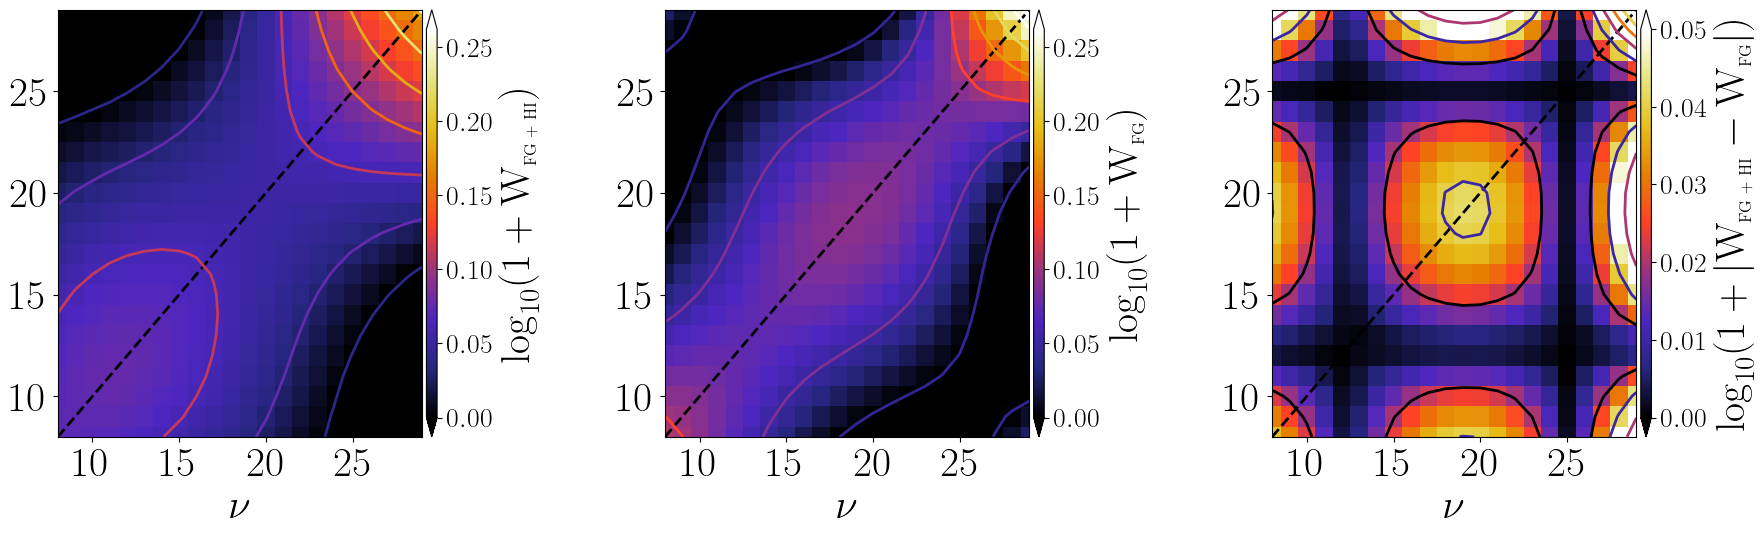

In [95]:
savefigs = True
nmin,nmax = 8,29
############################################################################
ncols,nrows = 3,1
fig, axes   = plt.subplots(nrows=nrows, ncols=ncols)
fig.subplots_adjust(top=nrows*1.,right=ncols*0.9, wspace=0.4,hspace=0.55)
############################################################################
cticks   = [10,15,20,25]
CMAP = 'CMRmap'
bwidth=3
WFGs = [dict_obs0['Wfg'],dict_obs1['Wfg'], np.abs(dict_obs0['Wfg']-dict_obs1['Wfg']) ]
#######
for ii, iWfg in enumerate(WFGs):#for ii, ins in enumerate(WFG_dict.keys()):
    ax  = axes[ii] 
    iWfg = iWfg[nmin:nmax+1,nmin:nmax+1]
    x    = np.arange(nmin,nmax+1,1)
    y    = np.arange(nmin,nmax+1,1)
    x,y = np.meshgrid(x, y)
    z   = np.log(1+iWfg)
    #######
    if ii<2:im = ax.pcolormesh(x, y, z, cmap=CMAP, vmin=np.log(1+0), vmax=np.log(1+0.3))
    else: im = ax.pcolormesh(x, y, z, cmap=CMAP, vmin=0, vmax=0.05)
    ax.plot(x[0,:],y[:,0], color='black',lw=2,ls='--')
    CS = ax.contour(   x, y, z, cmap=CMAP, extend='both',  linewidths=2,)
    cbar = plt.colorbar(im, ax=ax,extend='both',shrink=1.,pad=0.01,aspect=40, location="right")
    if ii==0:   cbar.set_label(label=r'$\log_{10}(1+\textrm{W}_{\textrm{\large FG + HI}})$', fontsize=30)
    elif ii==1: cbar.set_label(label=r'$\log_{10}(1+\textrm{W}_{\textrm{\large FG}})$', fontsize=30)    
    else:    cbar.set_label(label=r'$\log_{10}(1+|\textrm{W}_{\textrm{\large FG + HI}}-\textrm{W}_{\textrm{\large FG}}|)$', fontsize=30)
    cbar.ax.tick_params(labelsize=20) 
    ax.set_xticks(cticks)
    ax.set_yticks(cticks)
    ax.set_xlabel(r'$\nu$', fontsize=30)
    ax.tick_params(axis='both', labelsize=30)
    ax.set_xlabel(r'$\nu$', fontsize=30)
    ax.axis([x.min(), x.max(), y.min(), y.max()])
#axes[0].text(x=55, y=32, s=r'$\textbf{LOW-Z}$', 
#        fontdict={'family': 'serif', 'color': None,  'weight': 'bold','size': 30})
plt.show()

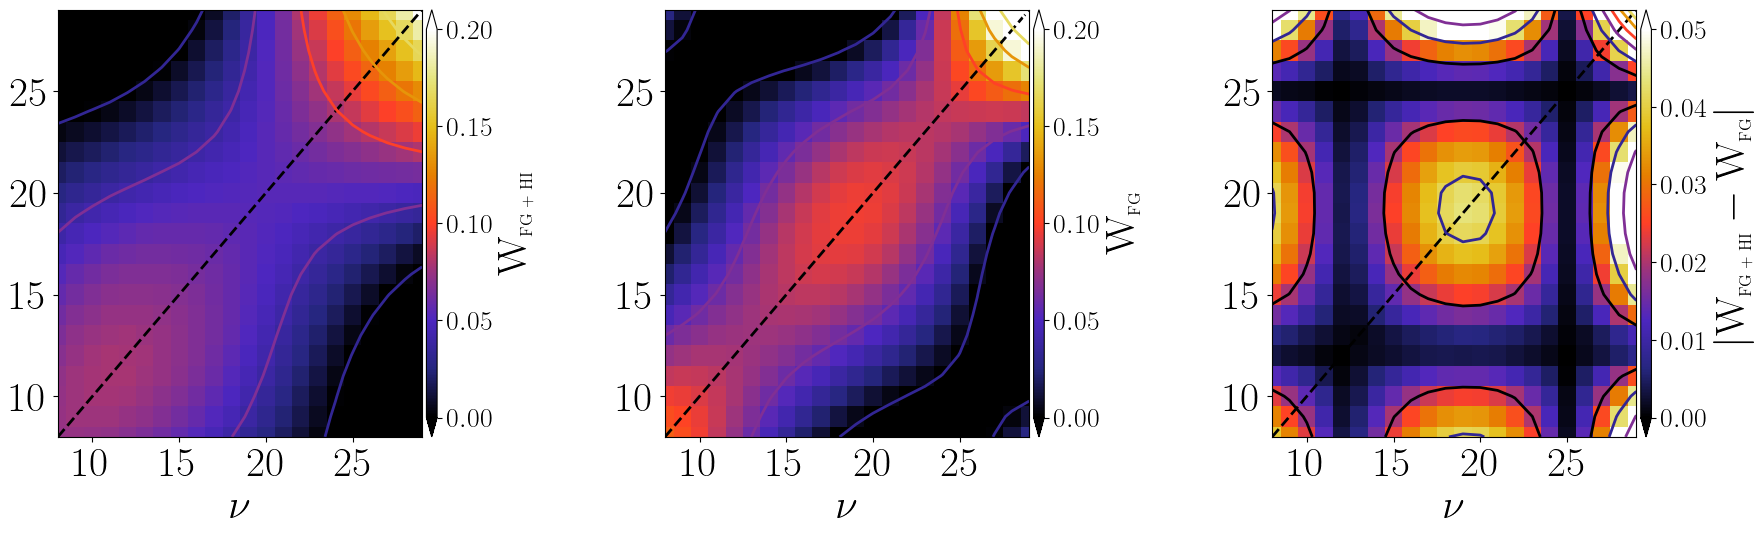

In [100]:
savefigs = True
nmin,nmax = 8,29
############################################################################
ncols,nrows = 3,1
fig, axes   = plt.subplots(nrows=nrows, ncols=ncols)
fig.subplots_adjust(top=nrows*1.,right=ncols*0.9, wspace=0.4,hspace=0.55)
############################################################################
cticks   = [10,15,20,25,30]
CMAP = 'CMRmap'
bwidth=3
WFGs = [dict_obs0['Wfg'],dict_obs1['Wfg'], np.abs(dict_obs0['Wfg']-dict_obs1['Wfg']) ]
#######
for ii, iWfg in enumerate(WFGs):#for ii, ins in enumerate(WFG_dict.keys()):
    ax  = axes[ii] 
    iWfg = iWfg[nmin:nmax+1,nmin:nmax+1]
    x    = np.arange(nmin,nmax+1,1)
    y    = np.arange(nmin,nmax+1,1)
    x,y = np.meshgrid(x, y)
    z   = iWfg
    #######
    if ii<2:im = ax.pcolormesh(x, y, z, cmap=CMAP, vmin=0.0, vmax=0.2)
    else: im = ax.pcolormesh(x, y, z, cmap=CMAP, vmin=0, vmax=0.05)
    ax.plot(x[0,:],y[:,0], color='black',lw=2,ls='--')
    CS = ax.contour(   x, y, z, cmap=CMAP, extend='both',  linewidths=2,)
    cbar = plt.colorbar(im, ax=ax,extend='both',shrink=1.,pad=0.01,aspect=40, location="right")
    if ii==0:   cbar.set_label(label=r'$\textrm{W}_\textrm{\large FG + HI}$', fontsize=30)
    elif ii==1: cbar.set_label(label=r'$\textrm{W}_\textrm{\large FG}$', fontsize=30)    
    else:    cbar.set_label(label=r'$|\textrm{W}_{\textrm{\large FG + HI}}-\textrm{W}_{\textrm{\large FG}}|$', fontsize=30)
    cbar.ax.tick_params(labelsize=20) 
    ax.set_xticks(cticks)
    ax.set_yticks(cticks)
    ax.set_xlabel(r'$\nu$', fontsize=30)
    ax.tick_params(axis='both', labelsize=30)
    ax.set_xlabel(r'$\nu$', fontsize=30)
    ax.axis([x.min(), x.max(), y.min(), y.max()])
#axes[0].text(x=55, y=32, s=r'$\textbf{LOW-Z}$', 
#        fontdict={'family': 'serif', 'color': None,  'weight': 'bold','size': 30})
plt.show()

In [103]:
dict_sims.keys()

dict_keys(['sim0', 'sim1', 'sim10', 'sim100', 'sim1000', 'sim1001', 'sim1002', 'sim1003', 'sim1004', 'sim1005', 'sim1006', 'sim1007', 'sim1008', 'sim1009', 'sim101', 'sim1010', 'sim1011', 'sim1012', 'sim1013', 'sim1014', 'sim1015', 'sim1016', 'sim1017', 'sim1018', 'sim1019', 'sim102', 'sim1020', 'sim1021', 'sim1022', 'sim1023', 'sim1024', 'sim1025', 'sim1026', 'sim1027', 'sim1028', 'sim1029', 'sim103', 'sim1030', 'sim1031', 'sim1032', 'sim1033', 'sim1034', 'sim1035', 'sim1036', 'sim1037', 'sim1038', 'sim1039', 'sim104', 'sim1040', 'sim1041', 'sim1042', 'sim1043', 'sim1044', 'sim1045', 'sim1046', 'sim1047', 'sim1048', 'sim1049', 'sim105', 'sim1050', 'sim1051', 'sim1052', 'sim1053', 'sim1054', 'sim1055', 'sim1056', 'sim1057', 'sim1058', 'sim1059', 'sim106', 'sim1060', 'sim1061', 'sim1062', 'sim1063', 'sim1064', 'sim1065', 'sim1066', 'sim1067', 'sim1068', 'sim1069', 'sim107', 'sim1070', 'sim1071', 'sim1072', 'sim1073', 'sim1074', 'sim1075', 'sim1076', 'sim1077', 'sim1078', 'sim1079', 'sim

In [104]:
wfg=0
for i,isim in enumerate(dict_sims.keys()):
    Mhi       = MHI_from_simulation(dict_=dict_sims, var_='alm_hi_sim', sim_=isim, nside=256, verbose=False)
    dict_obs0 = WICA(X_=Mfg+Mhi, ns=4)
    wfg += dict_obs0['Wfg']
wfg=wfg/len(dict_sims.keys())

In [105]:
Wfg0 = dcopy(wfg)

In [106]:
Wfg1 = WICA(X_=Mfg+0*Mhi, ns=4)['Wfg']

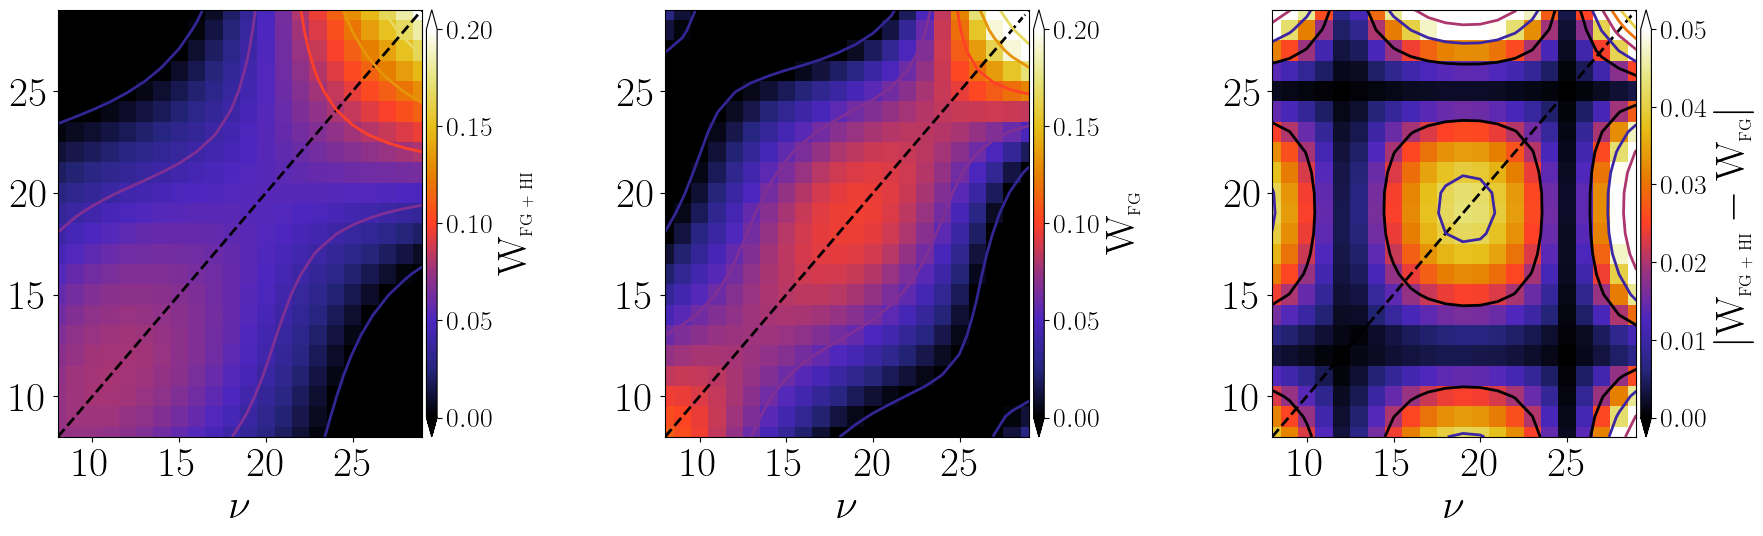

In [111]:
savefigs = True
nmin,nmax = 8,29
############################################################################
ncols,nrows = 3,1
fig, axes   = plt.subplots(nrows=nrows, ncols=ncols)
fig.subplots_adjust(top=nrows*1.,right=ncols*0.9, wspace=0.4,hspace=0.55)
############################################################################
cticks   = [10,15,20,25,30]
CMAP = 'CMRmap'
bwidth=3
WFGs = [Wfg0,Wfg1, np.abs(Wfg1-Wfg0) ]
#######
for ii, iWfg in enumerate(WFGs):#for ii, ins in enumerate(WFG_dict.keys()):
    ax  = axes[ii] 
    iWfg = iWfg[nmin:nmax+1,nmin:nmax+1]
    x    = np.arange(nmin,nmax+1,1)
    y    = np.arange(nmin,nmax+1,1)
    x,y = np.meshgrid(x, y)
    z   = iWfg
    #######
    if ii<2:im = ax.pcolormesh(x, y, z, cmap=CMAP, vmin=0.0, vmax=0.2)
    else: im = ax.pcolormesh(x, y, z, cmap=CMAP, vmin=0, vmax=0.05)
    ax.plot(x[0,:],y[:,0], color='black',lw=2,ls='--')
    CS = ax.contour(   x, y, z, cmap=CMAP, extend='both',  linewidths=2,)
    cbar = plt.colorbar(im, ax=ax,extend='both',shrink=1.,pad=0.01,aspect=40, location="right")
    if ii==0:   cbar.set_label(label=r'$\textrm{W}_\textrm{\large FG + HI}$', fontsize=30)
    elif ii==1: cbar.set_label(label=r'$\textrm{W}_\textrm{\large FG}$', fontsize=30)    
    else:    cbar.set_label(label=r'$|\textrm{W}_{\textrm{\large FG + HI}}-\textrm{W}_{\textrm{\large FG}}|$', fontsize=30)
    cbar.ax.tick_params(labelsize=20) 
    ax.set_xticks(cticks)
    ax.set_yticks(cticks)
    ax.set_xlabel(r'$\nu$', fontsize=30)
    ax.tick_params(axis='both', labelsize=30)
    ax.set_xlabel(r'$\nu$', fontsize=30)
    ax.axis([x.min(), x.max(), y.min(), y.max()])
#axes[0].text(x=55, y=32, s=r'$\textbf{LOW-Z}$', 
#        fontdict={'family': 'serif', 'color': None,  'weight': 'bold','size': 30})
plt.show()